In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/milk_prices.csv", parse_dates=["date"])
# Simple time feature: number of days since the first record
df["day_num"] = (df["date"] - df["date"].min()).dt.days
df.head()

,date,price,day_num
0,2022-01-01,0.553,0
1,2022-01-02,0.540,1
2,2022-01-03,0.559,2
3,2022-01-04,0.562,3
4,2022-01-05,0.533,4


In [13]:
split = int(len(df) * 0.8)
train, test = df.iloc[:split], df.iloc[split:]

print("Train:", train.shape, "| Test:", test.shape)
print("Train ends:", train["date"].max().date())
print("Test starts:", test["date"].min().date())

Train: (1412, 3) | Test: (353, 3)
Train ends: 2025-11-12
Test starts: 2025-11-13


In [14]:
X_train, y_train = train[["day_num"]], train["price"]
X_test, y_test = test[["day_num"]], test["price"]

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Slope (price change per day):", model.coef_[0])
print("Intercept:", model.intercept_)

Slope (price change per day): 4.81183775793846e-05
Intercept: 0.5587174987820501


In [15]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"MAE : {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2  : {r2:.4f}")

# Naive comparison: always predict the training mean
naive = np.full(len(y_test), y_train.mean())
print(f"\nNaive (train mean) MAE: {mean_absolute_error(y_test, naive):.4f}")

MAE : 0.0265
RMSE: 0.0307
R2  : -0.2796

Naive (train mean) MAE: 0.0527


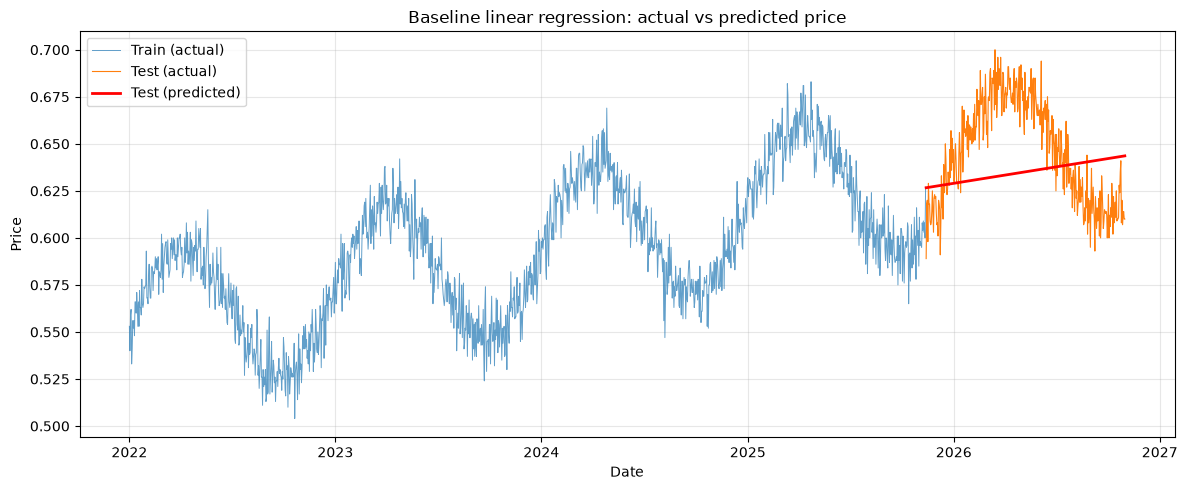

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(train["date"], train["price"], label="Train (actual)", linewidth=0.7, alpha=0.7)
plt.plot(test["date"], test["price"], label="Test (actual)", linewidth=0.8)
plt.plot(test["date"], pred, label="Test (predicted)", color="red", linewidth=2)
plt.title("Baseline linear regression: actual vs predicted price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()